# Centrifuge dataset: exploratory data analysis
Explore data quality, sensor trends, and the documented bearing-fault window (1–4 April 2025). Dates are kept in UTC; the assignment does not specify the label timezone. Records outside this window are **unlabelled**, not confirmed healthy. Raw waveform units and sampling rates should be verified before physical interpretations.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path("centrifuge line datasets.parquet")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
pf = pq.ParquetFile(DATA_PATH)
display(pd.DataFrame({"column": pf.schema_arrow.names,
                      "parquet_type": [str(f.type) for f in pf.schema_arrow]}))
print(f"Rows: {pf.metadata.num_rows:,}; file size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")

Matplotlib is building the font cache; this may take a moment.


,column,parquet_type
0,date,"timestamp[ns, tz=UTC]"
1,Motor DE_Z Short Wave High Frequency,list<element: double>
2,Motor DE_Z Long Wave High Frequency,list<element: double>
3,Motor DE_X Short Wave Low Frequency,list<element: double>
4,Motor DE_Y Short Wave Low Frequency,list<element: double>
5,Motor DE_Z Short Wave Low Frequency,list<element: double>
6,Motor DE_Temperature,list<element: double>
7,Motor DE_Z Short Wave Low Frequency RMS,double
8,Motor DE_X Short Wave Low Frequency RMS,double
9,Motor DE_Y Short Wave Low Frequency RMS,double


Rows: 26,502; file size: 499.8 MiB


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

DATA_PATH = "centrifuge line datasets.parquet"

pf = pq.ParquetFile(DATA_PATH)

# Read the first row group
df = pf.read_row_group(0).to_pandas()

print("Rows loaded:", len(df))
print("Columns:", df.columns.tolist())

# Inspect the first row
row = df.iloc[0]

print("Timestamp:", row["date"])

for col in df.columns:
    if col == "date":
        continue

    value = row[col]

    if isinstance(value, (list, np.ndarray)):
        print(f"{col}: waveform with {len(value)} samples")
    else:
        print(f"{col}: {value}")

Rows loaded: 26502
Columns: ['date', 'Motor DE_Z Short Wave High Frequency', 'Motor DE_Z Long Wave High Frequency', 'Motor DE_X Short Wave Low Frequency', 'Motor DE_Y Short Wave Low Frequency', 'Motor DE_Z Short Wave Low Frequency', 'Motor DE_Temperature', 'Motor DE_Z Short Wave Low Frequency RMS', 'Motor DE_X Short Wave Low Frequency RMS', 'Motor DE_Y Short Wave Low Frequency RMS', 'Motor DE_Z Speed Total Value', 'Motor DE_X Speed Total Value', 'Motor DE_Y Speed Total Value', 'Motor DE_Z Short Wave High Frequency RMS', 'Motor DE_Audio Decibels', 'Motor DE_Magnetic Leakage RMS', 'Motor DE_Audio Signal']
Timestamp: 2025-01-01 00:00:00+00:00
Motor DE_Z Short Wave High Frequency: waveform with 16384 samples
Motor DE_Z Long Wave High Frequency: None
Motor DE_X Short Wave Low Frequency: waveform with 5120 samples
Motor DE_Y Short Wave Low Frequency: waveform with 5120 samples
Motor DE_Z Short Wave Low Frequency: waveform with 9216 samples
Motor DE_Temperature: waveform with 1 samples
Motor 

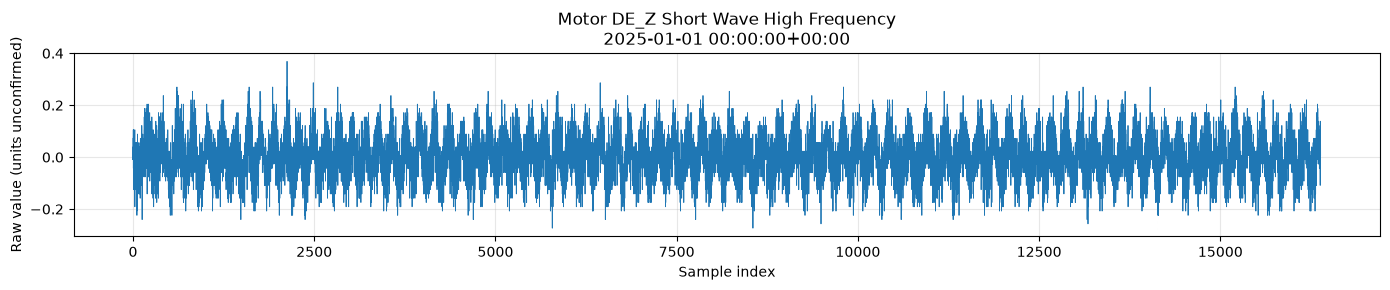

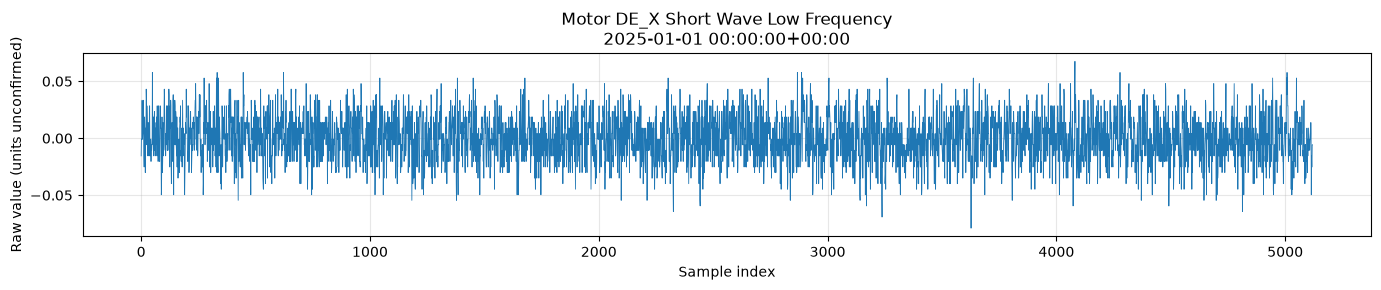

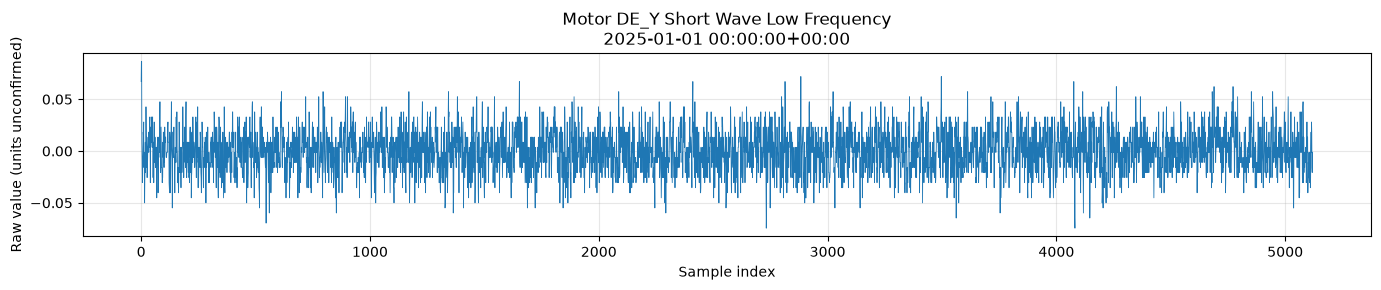

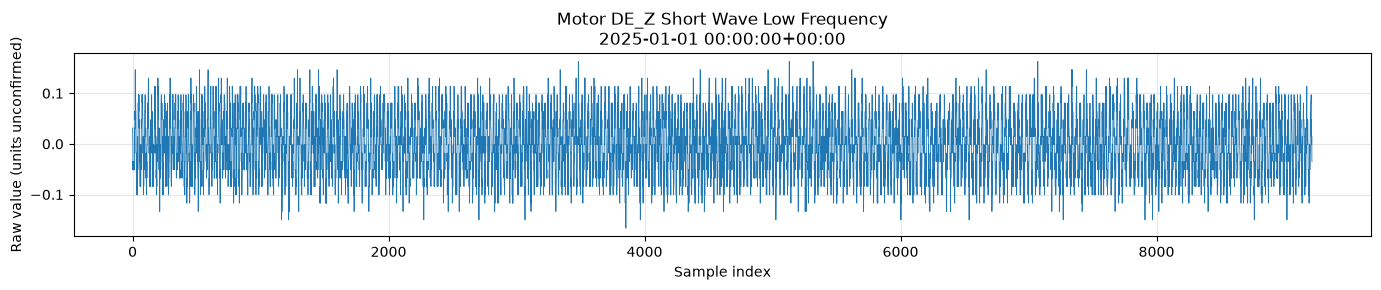

In [38]:
wave_cols = [
    col for col in pf.schema_arrow.names
    if ("Wave" in col and "RMS" not in col)
    or col == "Motor DE_Audio Signal"
]

first_row = next(
    pf.iter_batches(batch_size=1, columns=["date"] + wave_cols)
).to_pandas().iloc[0]

for col in wave_cols:
    value = first_row[col]
    if value is None:
        continue

    waveform = np.asarray(value, dtype=float).ravel()
    if waveform.size == 0:
        continue

    plt.figure(figsize=(14, 3))
    plt.plot(np.arange(waveform.size), waveform, linewidth=0.6)
    plt.title(f"{col}\n{first_row['date']}")
    plt.xlabel("Sample index")
    plt.ylabel("Raw value (units unconfirmed)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [18]:

df = pf.read().to_pandas()
df.shape


(26502, 17)

In [39]:
df.head()

,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal
0,2025-01-01 00:00:00+00:00,"[0.07242919803775294, -0.009920802701344655, 0...",None,"[-0.015489234076085268, -0.0008492343586112838...","[0.06706568620575126, 0.08658568582904991, 0.0...","[0.031227949499022856, 0.014757949351203337, -...",[36.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,2025-01-01 01:00:00+00:00,"[0.08318234693797422, 0.09965234708579374, 0.0...",None,"[-0.10952263851140742, -0.02656264011238818, -...","[-0.03109570252490812, -0.011575702901609475, ...","[-0.08909455158088164, -0.07262455143306212, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2,2025-01-01 02:00:00+00:00,"[-0.04962009749124263, 0.1480199042825916, -0....",None,"[-0.07613276415577275, 0.016587234054895816, 0...","[0.08604335771451588, -0.006676640496152686, -...","[0.10445296968747186, 0.08798296953965234, -0....",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3,2025-01-01 03:00:00+00:00,"[0.09775443691250985, -0.050475564417865826, 0...",None,"[-0.04607120223590755, 0.012488796633988386, 0...","[0.04633426473083091, -0.017105734044889687, -...","[-0.07933514719641366, -0.04639514690077462, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
4,2025-01-01 04:00:00+00:00,"[-0.03739928500363021, 0.0614207158832869, 0.1...",None,"[0.09517334191332338, -0.012186656014819164, -...","[-0.05530317080774694, -0.0601831707135716, -0...","[0.06496678769245534, -0.000913212898822735, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


In [22]:
print(df["Motor DE_Z Short Wave High Frequency"][0].shape)

(16384,)


In [36]:
df["date"].duplicated().sum()

np.int64(0)

In [23]:
# Load only the timestamp column
df_time = pf.read(columns=["date"]).to_pandas()

# Sort chronologically
df_time = df_time.sort_values("date").reset_index(drop=True)

# Calculate the time difference in seconds
df_time["gap_seconds"] = (
    df_time["date"].diff().dt.total_seconds()
)

display(df_time.head(20))

,date,gap_seconds
0,2025-01-01 00:00:00+00:00,NaN
1,2025-01-01 01:00:00+00:00,3600.0
2,2025-01-01 02:00:00+00:00,3600.0
3,2025-01-01 03:00:00+00:00,3600.0
4,2025-01-01 04:00:00+00:00,3600.0
5,2025-01-01 05:00:00+00:00,3600.0
6,2025-01-01 06:00:00+00:00,3600.0
7,2025-01-01 07:00:00+00:00,3600.0
8,2025-01-01 08:00:00+00:00,3600.0
9,2025-01-01 13:11:20+00:00,18680.0


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Signal columns
signal_columns = [
    "Motor DE_Z Short Wave High Frequency",
    "Motor DE_Z Long Wave High Frequency",
    "Motor DE_X Short Wave Low Frequency",
    "Motor DE_Y Short Wave Low Frequency",
    "Motor DE_Z Short Wave Low Frequency"
]

# Load only the required columns
df_signals = pf.read(columns=signal_columns).to_pandas()

# Calculate array lengths (NaN for missing arrays)
df_lengths = df_signals[signal_columns].apply(
    lambda col: col.map(
        lambda x: len(x) if x is not None else np.nan
    )
)

display(df_lengths.head(10))

,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency
0,16384.0,NaN,5120.0,5120.0,9216.0
1,16384.0,NaN,5120.0,5120.0,9216.0
2,16384.0,NaN,5120.0,5120.0,9216.0
3,16384.0,NaN,5120.0,5120.0,9216.0
4,16384.0,NaN,5120.0,5120.0,9216.0
5,16384.0,NaN,5120.0,5120.0,9216.0
6,16384.0,NaN,5120.0,5120.0,9216.0
7,16384.0,NaN,5120.0,5120.0,9216.0
8,16384.0,NaN,5120.0,5120.0,9216.0
9,NaN,NaN,NaN,NaN,NaN


In [32]:
summary = pd.DataFrame({
    "Min Length": df_lengths.min(),
    "Max Length": df_lengths.max(),
    "Mean Length": df_lengths.mean(),
    "Unique Lengths": df_lengths.nunique(),
    "Missing Records": df_lengths.isna().sum(),
    "Empty Arrays": (df_lengths == 0).sum(),
    "Same Length Across Records": (
        (df_lengths.nunique() == 1) &
        df_lengths.notna().all()
    )
})

display(summary)

,Min Length,Max Length,Mean Length,Unique Lengths,Missing Records,Empty Arrays,Same Length Across Records
Motor DE_Z Short Wave High Frequency,16384.0,16384.0,16384.0,1,23823,0,False
Motor DE_Z Long Wave High Frequency,131072.0,131072.0,131072.0,1,25877,0,False
Motor DE_X Short Wave Low Frequency,5120.0,5120.0,5120.0,1,23826,0,False
Motor DE_Y Short Wave Low Frequency,5120.0,5120.0,5120.0,1,23824,0,False
Motor DE_Z Short Wave Low Frequency,9216.0,9216.0,9216.0,1,23826,0,False


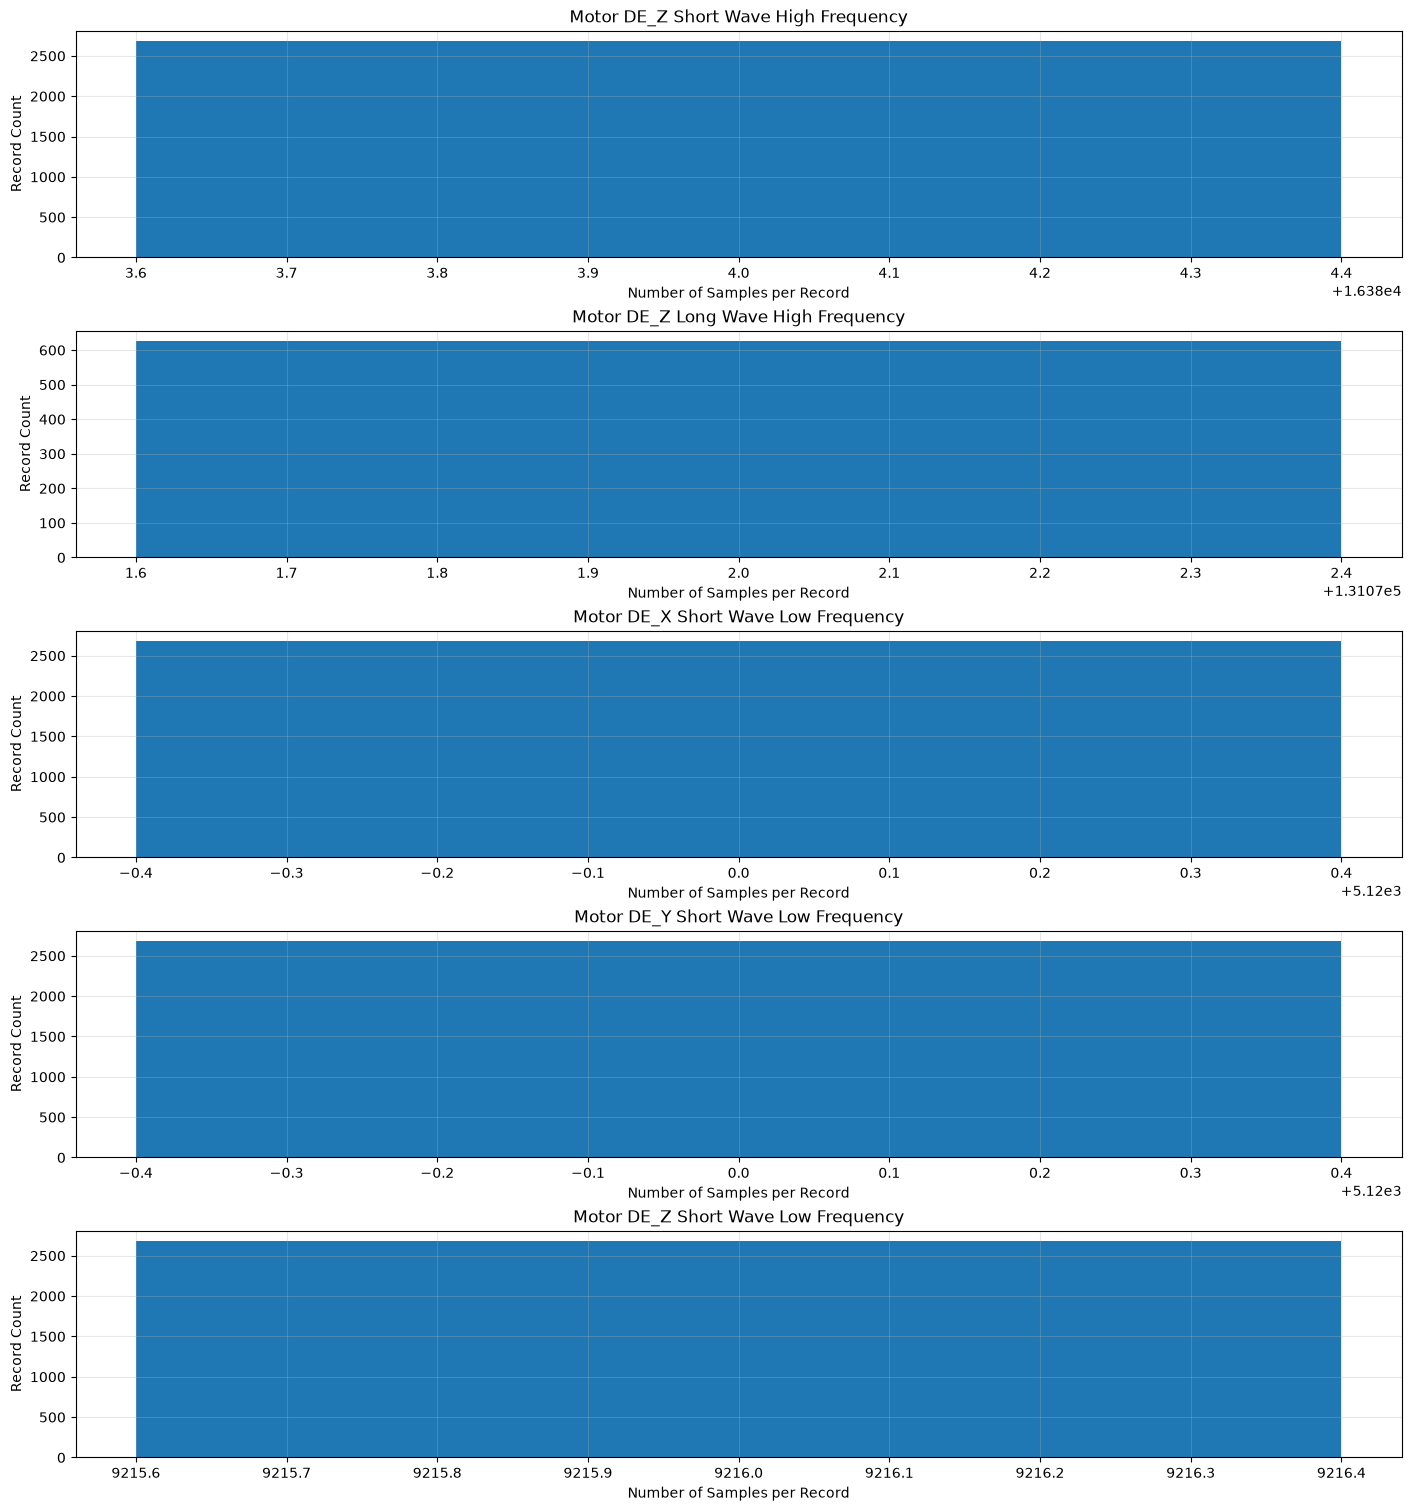

In [33]:
fig, axes = plt.subplots(
    len(signal_columns),
    1,
    figsize=(14, 3 * len(signal_columns)),
    constrained_layout=True
)

for ax, col in zip(axes, signal_columns):

    counts = df_lengths[col].value_counts().sort_index()

    ax.bar(counts.index, counts.values)

    ax.set_title(col)
    ax.set_xlabel("Number of Samples per Record")
    ax.set_ylabel("Record Count")
    ax.grid(True, alpha=0.3)

plt.show()

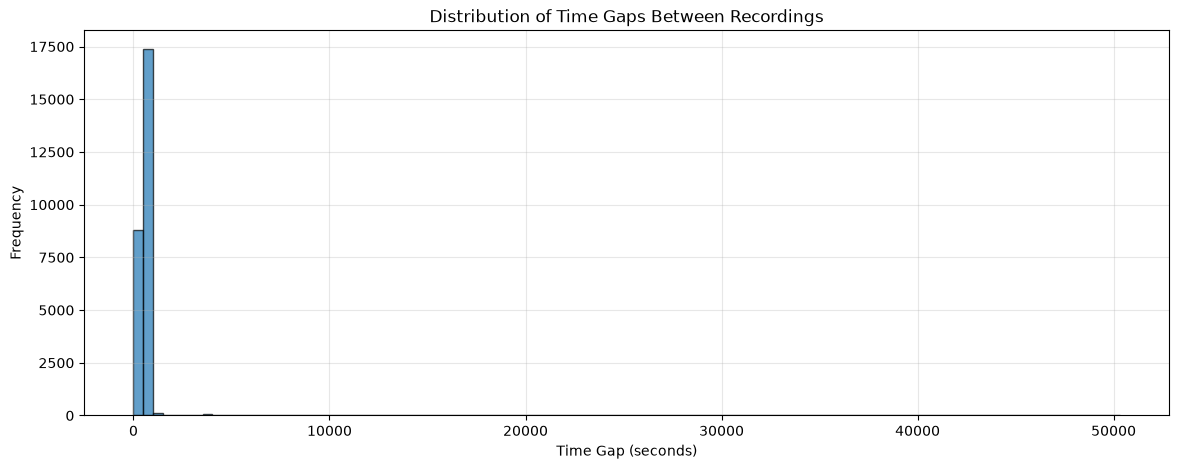

Minimum gap: 1.0 seconds
Maximum gap: 50318.0 seconds
Mean gap: 521.6406173351949 seconds
Median gap: 580.0 seconds
Standard deviation: 2163.256690298737 seconds
Unique gap values: 116


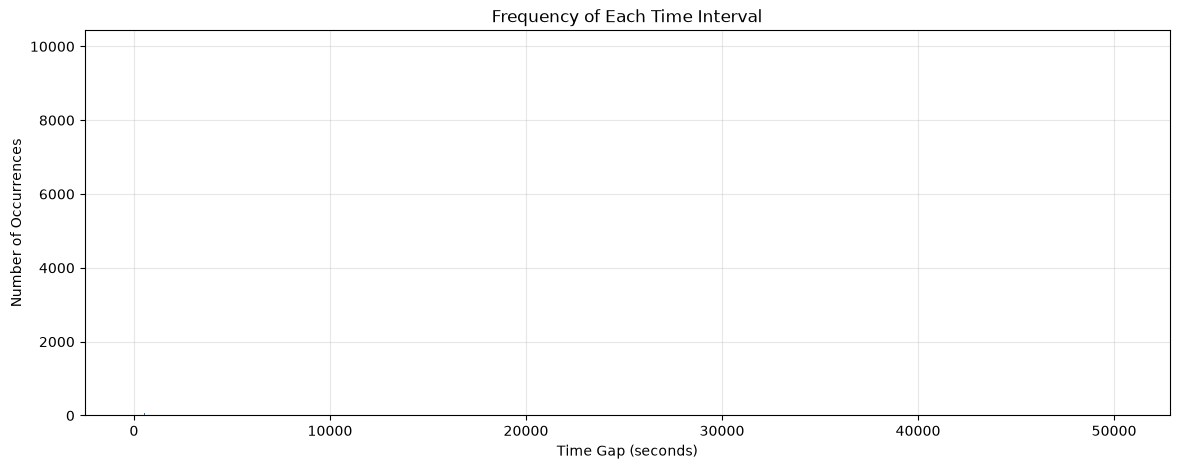

,Gap (seconds),Count
0,600.0,9934
1,20.0,3111
2,518.0,2606
3,580.0,2585
4,2.0,2507
...,...,...
111,2340.0,1
112,34139.0,1
113,1820.0,1
114,14999.0,1


In [26]:
gaps = df_time["date"].diff().dt.total_seconds().dropna()

# Plot distribution
plt.figure(figsize=(14, 5))

plt.hist(gaps, bins=100, edgecolor="black", alpha=0.7)

plt.xlabel("Time Gap (seconds)")
plt.ylabel("Frequency")
plt.title("Distribution of Time Gaps Between Recordings")
plt.grid(True, alpha=0.3)

plt.show()

# Show statistics
print("Minimum gap:", gaps.min(), "seconds")
print("Maximum gap:", gaps.max(), "seconds")
print("Mean gap:", gaps.mean(), "seconds")
print("Median gap:", gaps.median(), "seconds")
print("Standard deviation:", gaps.std(), "seconds")
print("Unique gap values:", gaps.nunique())


# Count occurrences of each gap duration
gap_counts = gaps.value_counts().sort_index()

plt.figure(figsize=(14, 5))

plt.bar(
    gap_counts.index,
    gap_counts.values,
    width=0.8
)

plt.xlabel("Time Gap (seconds)")
plt.ylabel("Number of Occurrences")
plt.title("Frequency of Each Time Interval")
plt.grid(True, alpha=0.3)

plt.show()

display(
    gaps.value_counts()
        .rename_axis("Gap (seconds)")
        .reset_index(name="Count")
)

(0.0, 1200.0)

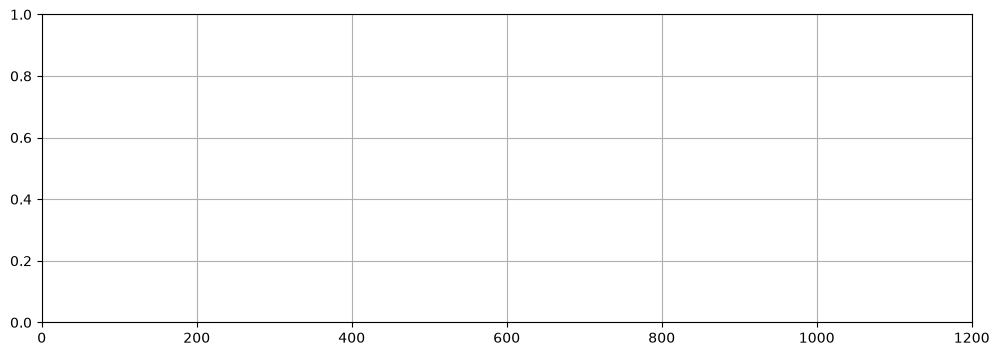

In [27]:
plt.xlim(0, gaps.quantile(0.99))

In [9]:
# Load the dataset
df = pf.read().to_pandas()

results = []

for col in df.columns:

    series = df[col]
    is_waveform = pa.types.is_list(
        pf.schema_arrow.field(col).type
    )

    missing = series.isna().sum()

    empty_arrays = 0
    arrays_with_nan = 0
    arrays_with_inf = 0
    min_length = None
    max_length = None

    if is_waveform:
        lengths = []

        for value in series.dropna():

            arr = np.asarray(value, dtype=float)

            lengths.append(len(arr))

            if len(arr) == 0:
                empty_arrays += 1

            if np.isnan(arr).any():
                arrays_with_nan += 1

            if np.isinf(arr).any():
                arrays_with_inf += 1

        if lengths:
            min_length = min(lengths)
            max_length = max(lengths)

    else:
        # Scalar numeric columns
        if pd.api.types.is_numeric_dtype(series):
            arrays_with_inf = np.isinf(
                series.dropna().to_numpy()
            ).sum()

    results.append({
        "Column": col,
        "Type": "Waveform" if is_waveform else "Scalar / Date",
        "Total Rows": len(series),
        "Missing": missing,
        "Missing %": round(missing / len(series) * 100, 2),
        "Empty Arrays": empty_arrays,
        "With NaN": arrays_with_nan,
        "With Inf": arrays_with_inf,
        "Min Samples": min_length,
        "Max Samples": max_length
    })

completeness_df = pd.DataFrame(results)

display(completeness_df)

,Column,Type,Total Rows,Missing,Missing %,Empty Arrays,With NaN,With Inf,Min Samples,Max Samples
0,date,Scalar / Date,26502,0,0.00,0,0,0,NaN,NaN
1,Motor DE_Z Short Wave High Frequency,Waveform,26502,23823,89.89,0,0,0,16384.0,16384.0
2,Motor DE_Z Long Wave High Frequency,Waveform,26502,25877,97.64,0,0,0,131072.0,131072.0
3,Motor DE_X Short Wave Low Frequency,Waveform,26502,23826,89.90,0,0,0,5120.0,5120.0
4,Motor DE_Y Short Wave Low Frequency,Waveform,26502,23824,89.90,0,0,0,5120.0,5120.0
5,Motor DE_Z Short Wave Low Frequency,Waveform,26502,23826,89.90,0,0,0,9216.0,9216.0
6,Motor DE_Temperature,Waveform,26502,23802,89.81,0,0,0,1.0,1.0
7,Motor DE_Z Short Wave Low Frequency RMS,Scalar / Date,26502,23146,87.34,0,0,0,NaN,NaN
8,Motor DE_X Short Wave Low Frequency RMS,Scalar / Date,26502,26367,99.49,0,0,0,NaN,NaN
9,Motor DE_Y Short Wave Low Frequency RMS,Scalar / Date,26502,26380,99.54,0,0,0,NaN,NaN


In [29]:
df.dtypes

date                                        datetime64[ns, UTC]
Motor DE_Z Short Wave High Frequency                     object
Motor DE_Z Long Wave High Frequency                      object
Motor DE_X Short Wave Low Frequency                      object
Motor DE_Y Short Wave Low Frequency                      object
Motor DE_Z Short Wave Low Frequency                      object
Motor DE_Temperature                                     object
Motor DE_Z Short Wave Low Frequency RMS                 float64
Motor DE_X Short Wave Low Frequency RMS                 float64
Motor DE_Y Short Wave Low Frequency RMS                 float64
Motor DE_Z Speed Total Value                            float64
Motor DE_X Speed Total Value                            float64
Motor DE_Y Speed Total Value                            float64
Motor DE_Z Short Wave High Frequency RMS                float64
Motor DE_Audio Decibels                                 float64
Motor DE_Magnetic Leakage RMS           

In [30]:
df.head()

,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal
0,2025-01-01 00:00:00+00:00,"[0.07242919803775294, -0.009920802701344655, 0...",None,"[-0.015489234076085268, -0.0008492343586112838...","[0.06706568620575126, 0.08658568582904991, 0.0...","[0.031227949499022856, 0.014757949351203337, -...",[36.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,2025-01-01 01:00:00+00:00,"[0.08318234693797422, 0.09965234708579374, 0.0...",None,"[-0.10952263851140742, -0.02656264011238818, -...","[-0.03109570252490812, -0.011575702901609475, ...","[-0.08909455158088164, -0.07262455143306212, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2,2025-01-01 02:00:00+00:00,"[-0.04962009749124263, 0.1480199042825916, -0....",None,"[-0.07613276415577275, 0.016587234054895816, 0...","[0.08604335771451588, -0.006676640496152686, -...","[0.10445296968747186, 0.08798296953965234, -0....",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3,2025-01-01 03:00:00+00:00,"[0.09775443691250985, -0.050475564417865826, 0...",None,"[-0.04607120223590755, 0.012488796633988386, 0...","[0.04633426473083091, -0.017105734044889687, -...","[-0.07933514719641366, -0.04639514690077462, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
4,2025-01-01 04:00:00+00:00,"[-0.03739928500363021, 0.0614207158832869, 0.1...",None,"[0.09517334191332338, -0.012186656014819164, -...","[-0.05530317080774694, -0.0601831707135716, -0...","[0.06496678769245534, -0.000913212898822735, 0...",[35.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


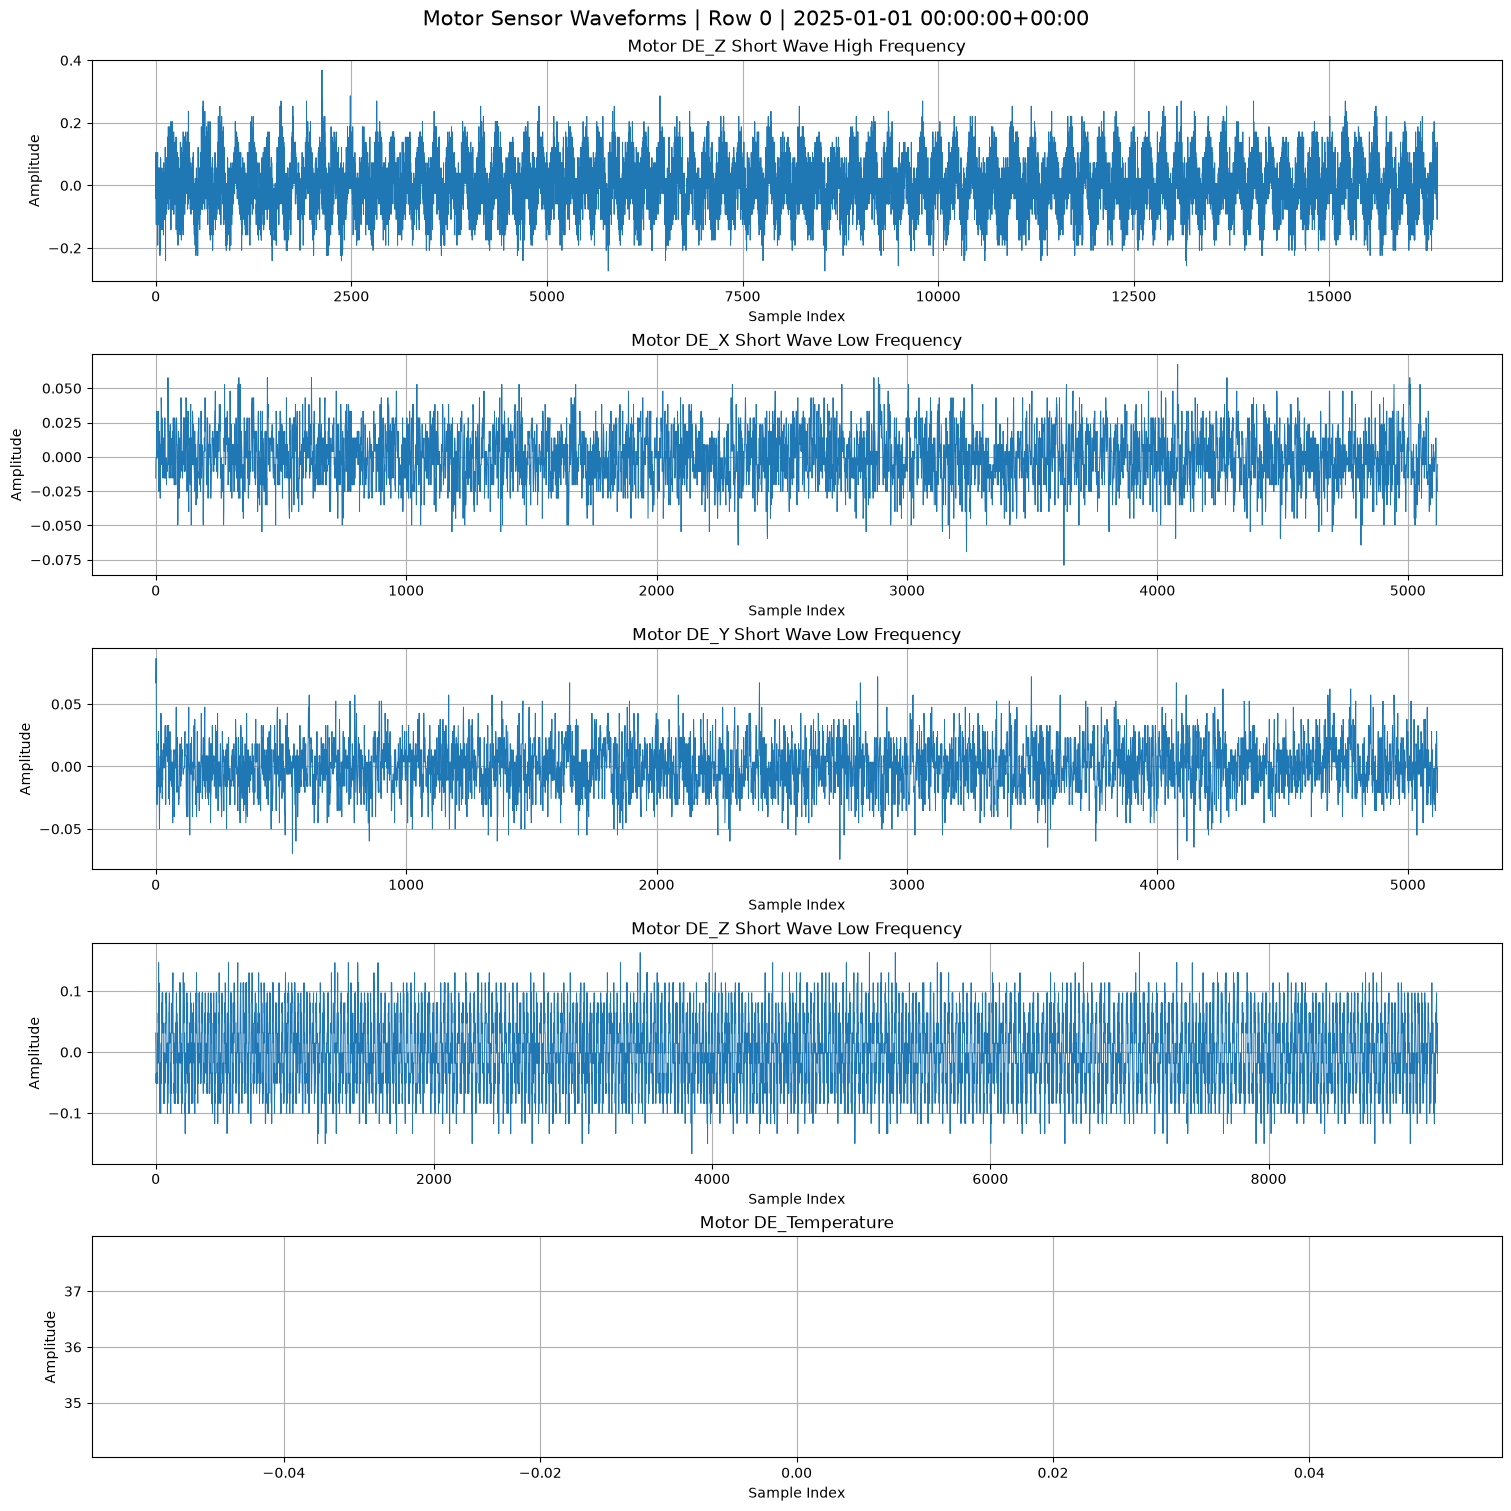

In [8]:
# Select a row
row_index = 0
row = df.iloc[row_index]

# Identify waveform columns
waveform_columns = [
    col for col in df.columns
    if isinstance(row[col], (list, np.ndarray))
]

n = len(waveform_columns)

fig, axes = plt.subplots(
    n,
    1,
    figsize=(15, 3 * n),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, col in zip(axes, waveform_columns):

    signal = np.asarray(row[col], dtype=float)

    ax.plot(signal, linewidth=0.7)
    ax.set_title(col)
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

fig.suptitle(
    f"Motor Sensor Waveforms | Row {row_index} | {row['date']}",
    fontsize=15
)

plt.show()

## Load scalar measurements
Read scalar columns first to avoid loading every large waveform into memory. Temperature is stored as an array; retain its mean and array length.

In [2]:
array_cols = [f.name for f in pf.schema_arrow if pa.types.is_list(f.type) or pa.types.is_large_list(f.type)]
scalar_cols = [name for name in pf.schema_arrow.names if name not in array_cols]
df = pd.read_parquet(DATA_PATH, columns=scalar_cols + ["Motor DE_Temperature"])
def finite_array(value):
    if value is None:
        return np.array([], dtype=float)
    a = np.asarray(value, dtype=float).ravel()
    return a[np.isfinite(a)]
temperature = df.pop("Motor DE_Temperature")
df["temperature_mean"] = temperature.map(lambda v: finite_array(v).mean() if finite_array(v).size else np.nan)
df["temperature_sample_count"] = temperature.map(lambda v: np.asarray(v).size if v is not None else 0)
df["date"] = pd.to_datetime(df["date"], utc=True, errors="coerce")
FAULT_START = pd.Timestamp("2025-04-01", tz="UTC")
FAULT_END = pd.Timestamp("2025-04-05", tz="UTC")  # exclusive; includes all of 4 April
print("Invalid dates:", df["date"].isna().sum())
print("Duplicate timestamps:", df["date"].duplicated().sum())
df = df.sort_values("date").reset_index(drop=True)
df["period"] = np.where(df["date"].between(FAULT_START, FAULT_END, inclusive="left"),
                        "Labelled fault", "Unlabelled")
print("Date range:", df["date"].min(), "to", df["date"].max())
display(df.head())
display(df["period"].value_counts().rename("records").to_frame())

Invalid dates: 0
Duplicate timestamps: 0
Date range: 2025-01-01 00:00:00+00:00 to 2025-06-09 23:59:58+00:00


,date,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,temperature_mean,temperature_sample_count,period
0,2025-01-01 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.0,1,Unlabelled
1,2025-01-01 01:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.0,1,Unlabelled
2,2025-01-01 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.0,1,Unlabelled
3,2025-01-01 03:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.0,1,Unlabelled
4,2025-01-01 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.0,1,Unlabelled


,records
period,
Unlabelled,26474
Labelled fault,28


## Missingness, distributions, and collection gaps

,missing_pct,infinite_count,unique_values
Motor DE_Audio Decibels,99.981133,0,5
Motor DE_Magnetic Leakage RMS,99.981133,0,5
Motor DE_Y Speed Total Value,99.800015,0,53
Motor DE_Y Short Wave Low Frequency RMS,99.539657,0,109
Motor DE_X Short Wave Low Frequency RMS,99.490604,0,112
Motor DE_X Speed Total Value,99.083088,0,241
Motor DE_Z Speed Total Value,97.192665,0,736
temperature_mean,89.812090,0,53
Motor DE_Z Short Wave Low Frequency RMS,87.336805,0,3172
Motor DE_Z Short Wave High Frequency RMS,26.835711,0,14910


,count,mean,std,min,25%,50%,75%,max
Motor DE_Z Short Wave Low Frequency RMS,3356.0,2.584945,2.595216,0.02977,0.067890,2.40394,5.800485,8.94486
Motor DE_X Short Wave Low Frequency RMS,135.0,2.277567,4.446032,0.01872,0.019660,0.02012,0.022885,14.05932
Motor DE_Y Short Wave Low Frequency RMS,122.0,2.656227,5.989403,0.01968,0.020530,0.02104,0.030883,18.53792
Motor DE_Z Speed Total Value,744.0,1.530135,1.783023,0.03922,0.096125,0.86123,2.009980,8.61478
Motor DE_X Speed Total Value,243.0,1.698218,2.421327,0.02293,0.029965,0.06354,4.669955,7.39895
Motor DE_Y Speed Total Value,53.0,0.420442,1.187588,0.02315,0.027780,0.03347,0.050530,5.27543
Motor DE_Z Short Wave High Frequency RMS,19390.0,12.921723,12.642957,0.04698,0.079863,16.26030,25.312732,40.54972
Motor DE_Audio Decibels,5.0,42.439408,22.722898,25.27240,25.816610,26.45430,67.294090,67.35964
Motor DE_Magnetic Leakage RMS,5.0,4.418028,2.485062,0.00000,5.049030,5.64365,5.663770,5.73369
temperature_mean,2700.0,44.819630,10.868665,28.00000,36.000000,39.00000,55.000000,83.00000


,gap_seconds
count,26501.000000
mean,521.640617
std,2163.256690
min,1.000000
25%,62.000000
50%,580.000000
75%,600.000000
max,50318.000000


Median positive gap (seconds): 580.0


,date
1,2025-01-01 01:00:00+00:00
2,2025-01-01 02:00:00+00:00
3,2025-01-01 03:00:00+00:00
4,2025-01-01 04:00:00+00:00
5,2025-01-01 05:00:00+00:00
6,2025-01-01 06:00:00+00:00
7,2025-01-01 07:00:00+00:00
8,2025-01-01 08:00:00+00:00
9,2025-01-01 13:11:20+00:00
14,2025-01-01 23:00:00+00:00


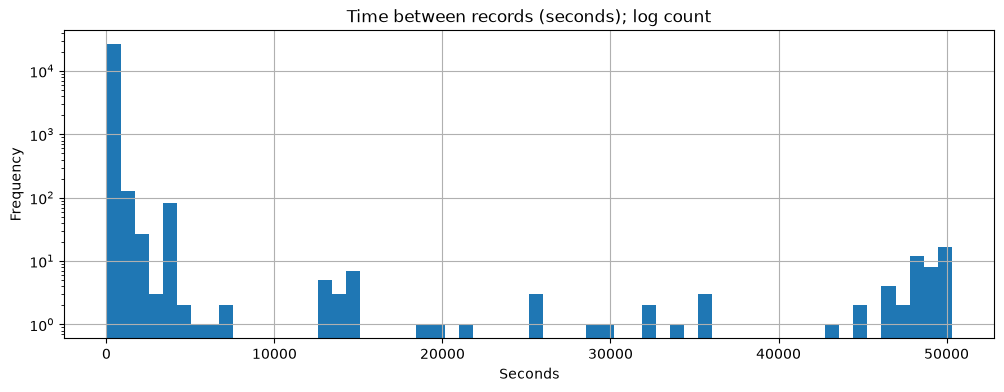

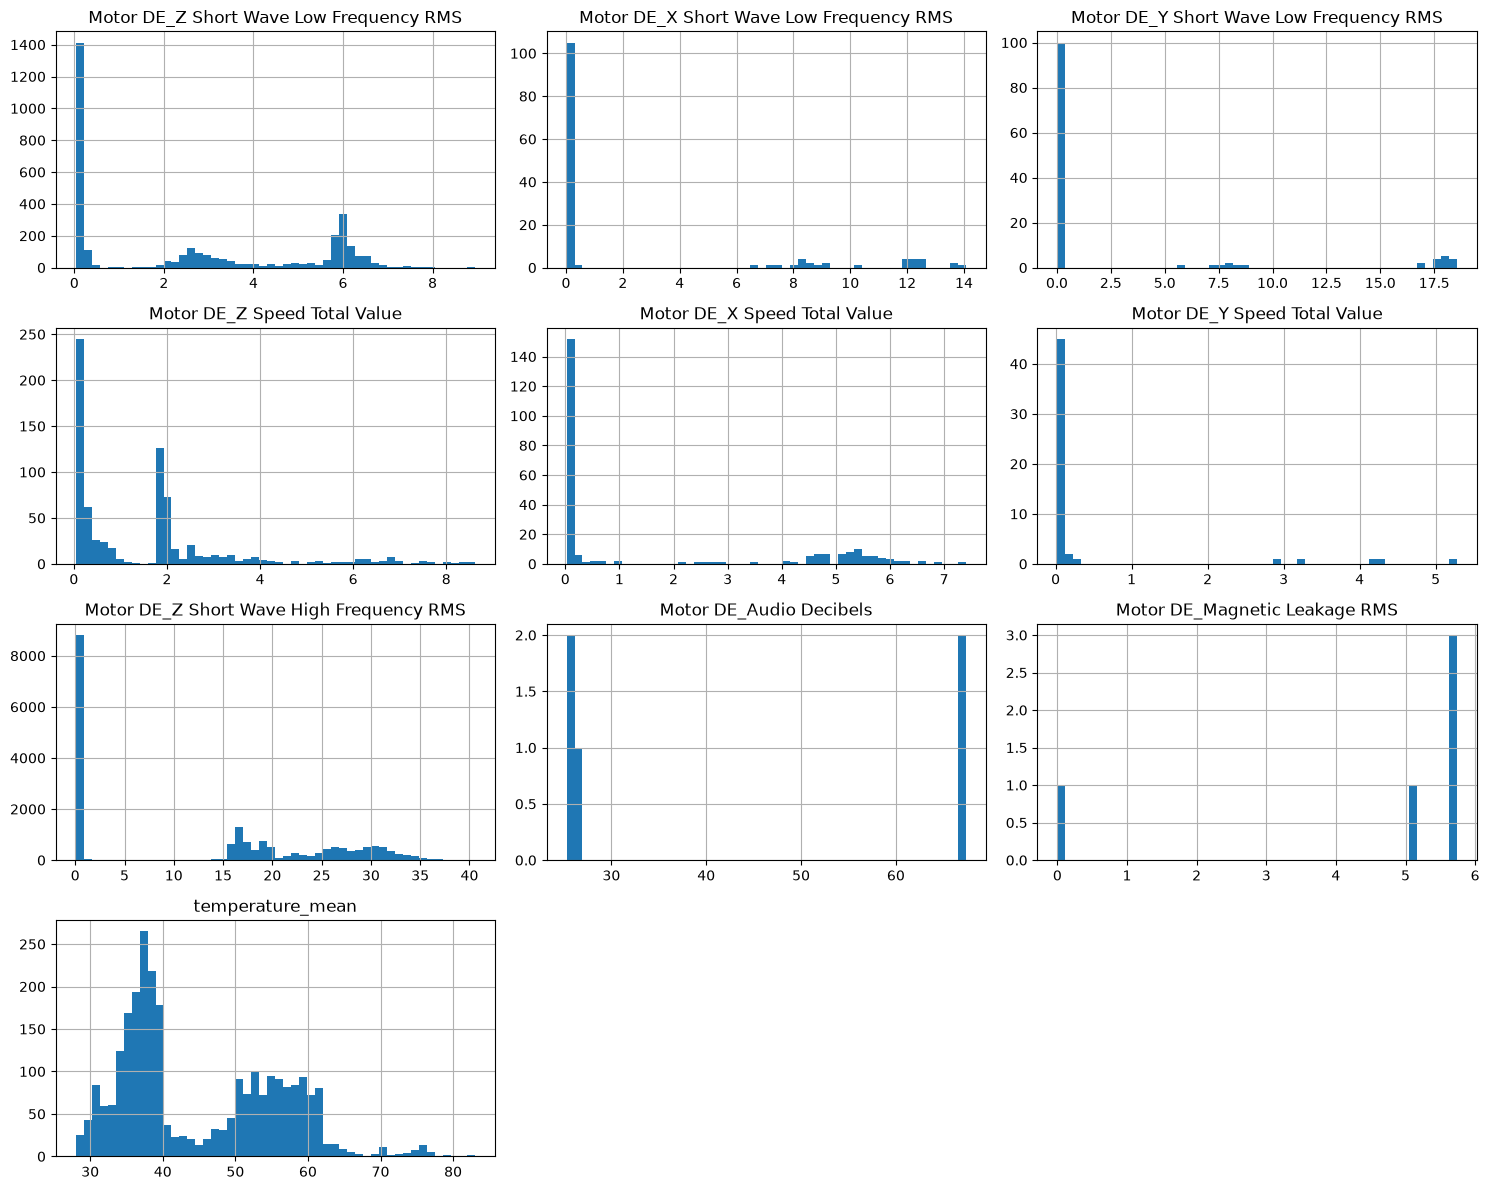

In [3]:
measure_cols = [col for col in df.select_dtypes(include="number").columns
                if col != "temperature_sample_count"]
quality = pd.DataFrame({"missing_pct": df[measure_cols].isna().mean() * 100,
                        "infinite_count": np.isinf(df[measure_cols]).sum(),
                        "unique_values": df[measure_cols].nunique()})
display(quality.sort_values("missing_pct", ascending=False))
display(df[measure_cols].describe().T)
gaps = df["date"].dropna().diff().dt.total_seconds().dropna()
display(gaps.describe().rename("gap_seconds").to_frame())
if not gaps.empty:
    typical_gap = gaps[gaps > 0].median()
    print("Median positive gap (seconds):", typical_gap)
    display(df.loc[df["date"].diff().dt.total_seconds() > 3 * typical_gap, ["date"]].head(20))
    gaps.plot.hist(bins=60, log=True, title="Time between records (seconds); log count")
    plt.xlabel("Seconds")
    plt.show()
df[measure_cols].hist(bins=50, figsize=(15, 12))
plt.tight_layout()
plt.show()

## Sensor trends and fault-period comparison
Daily medians simplify the overview. Inspect raw measurements near the fault window as well. Differences are descriptive associations, not evidence that a sensor alone identifies faults; operating conditions can confound them.

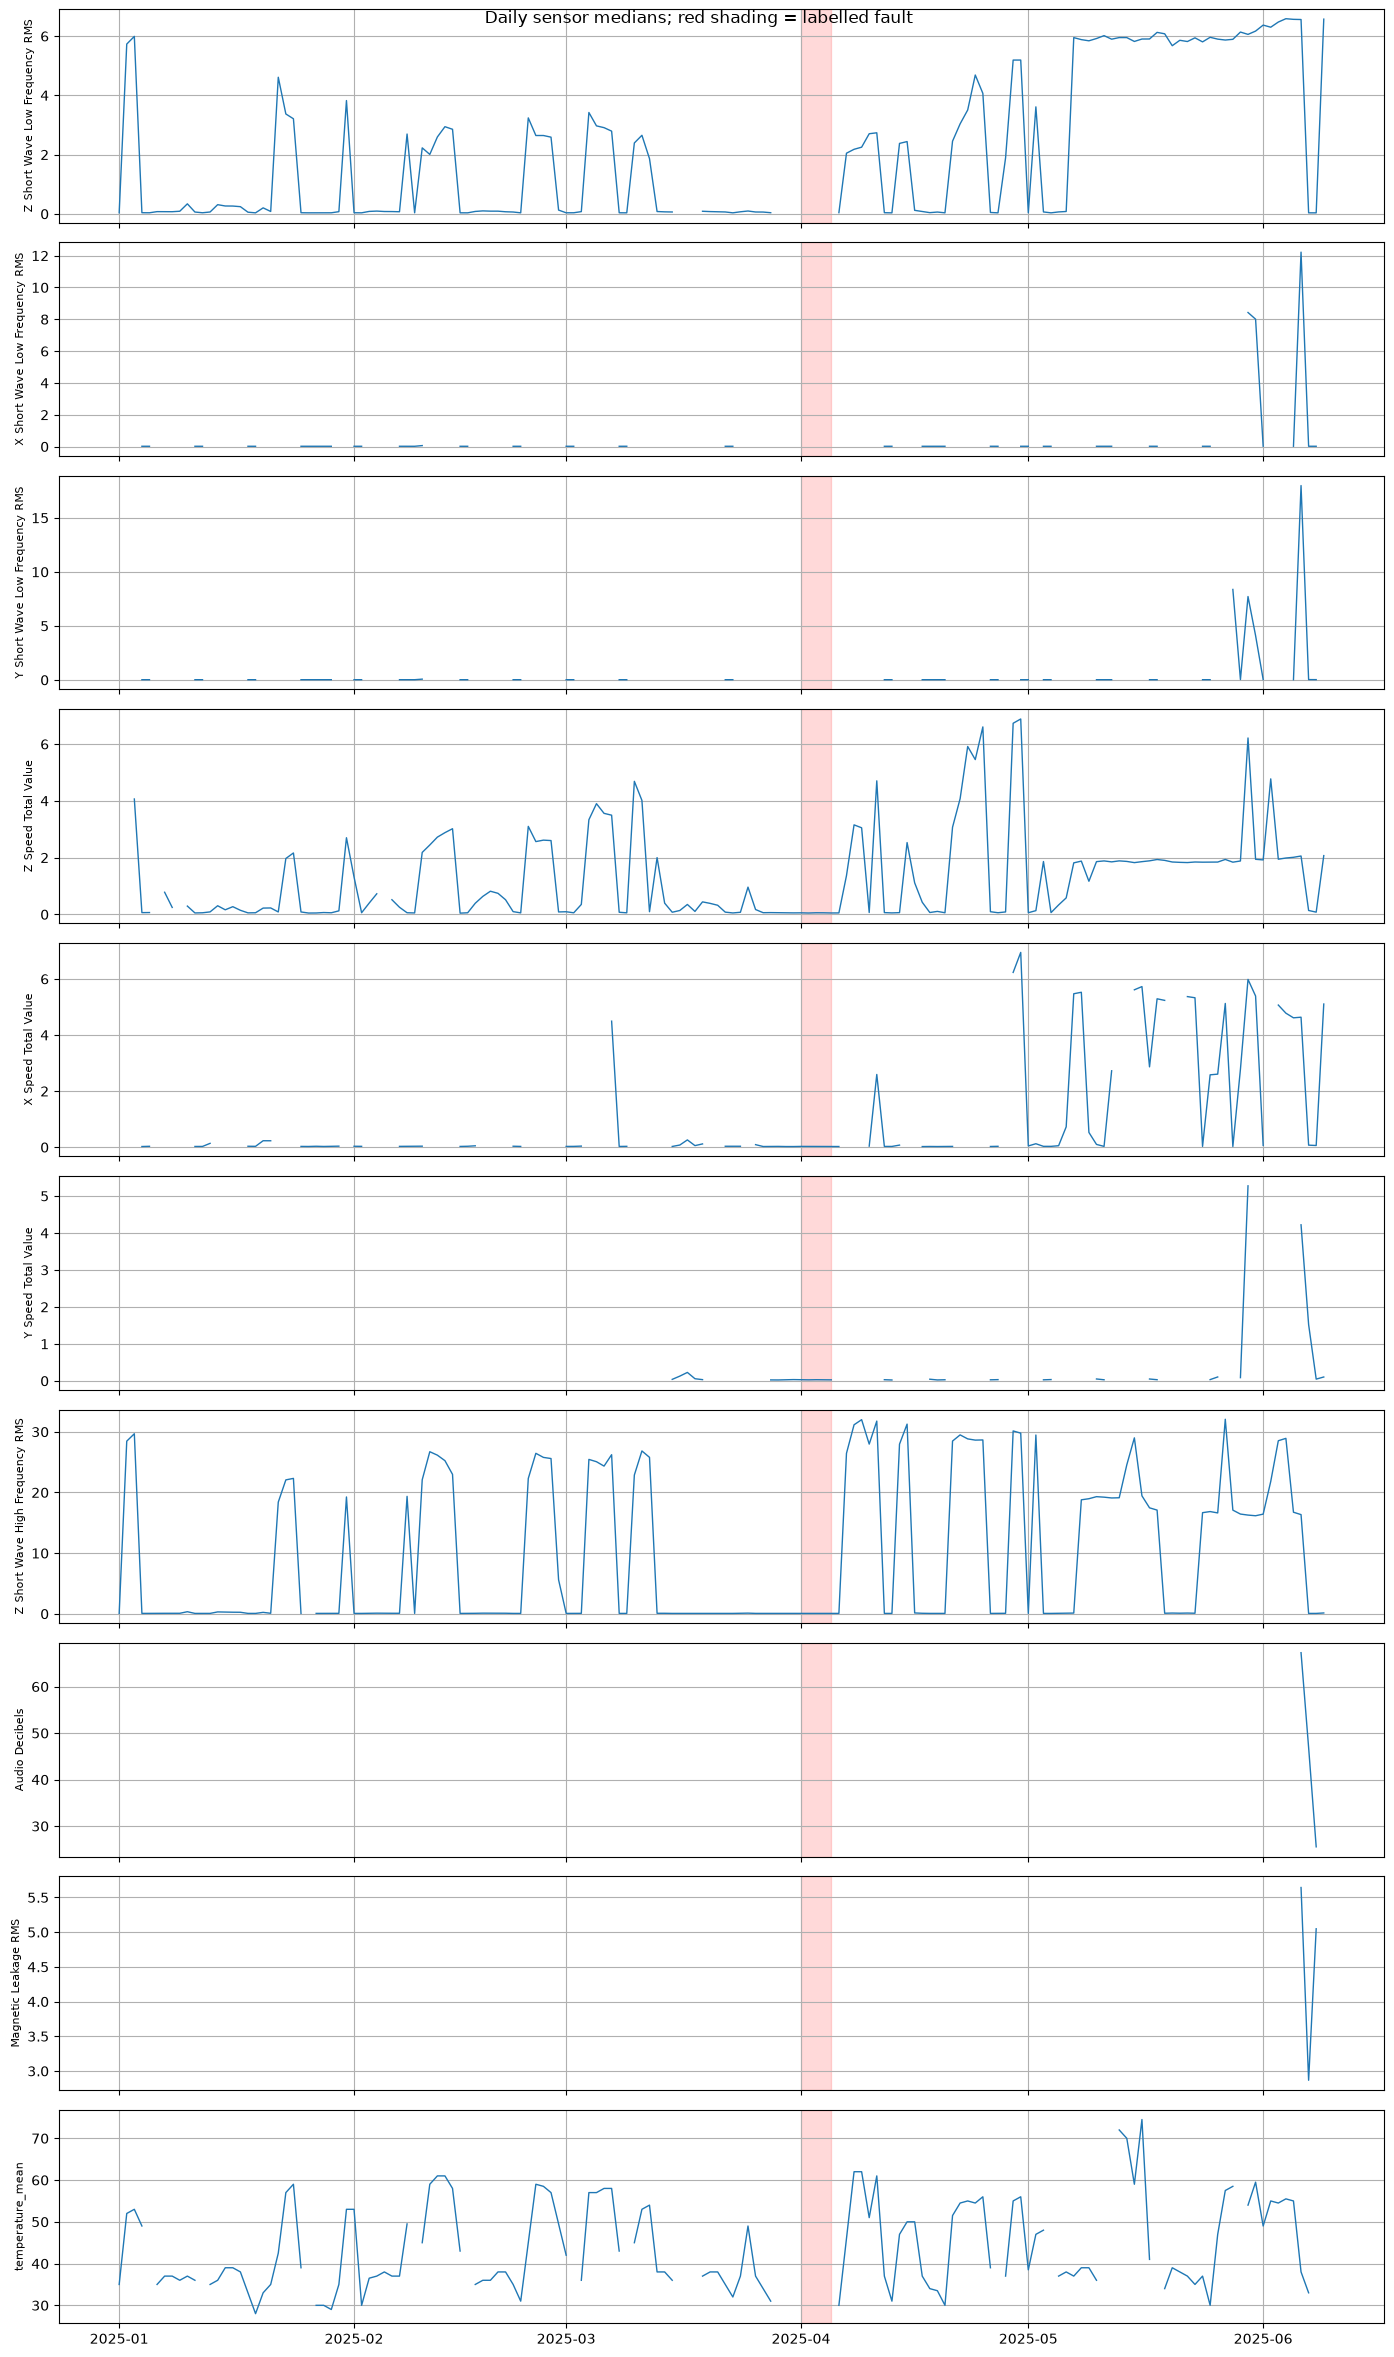

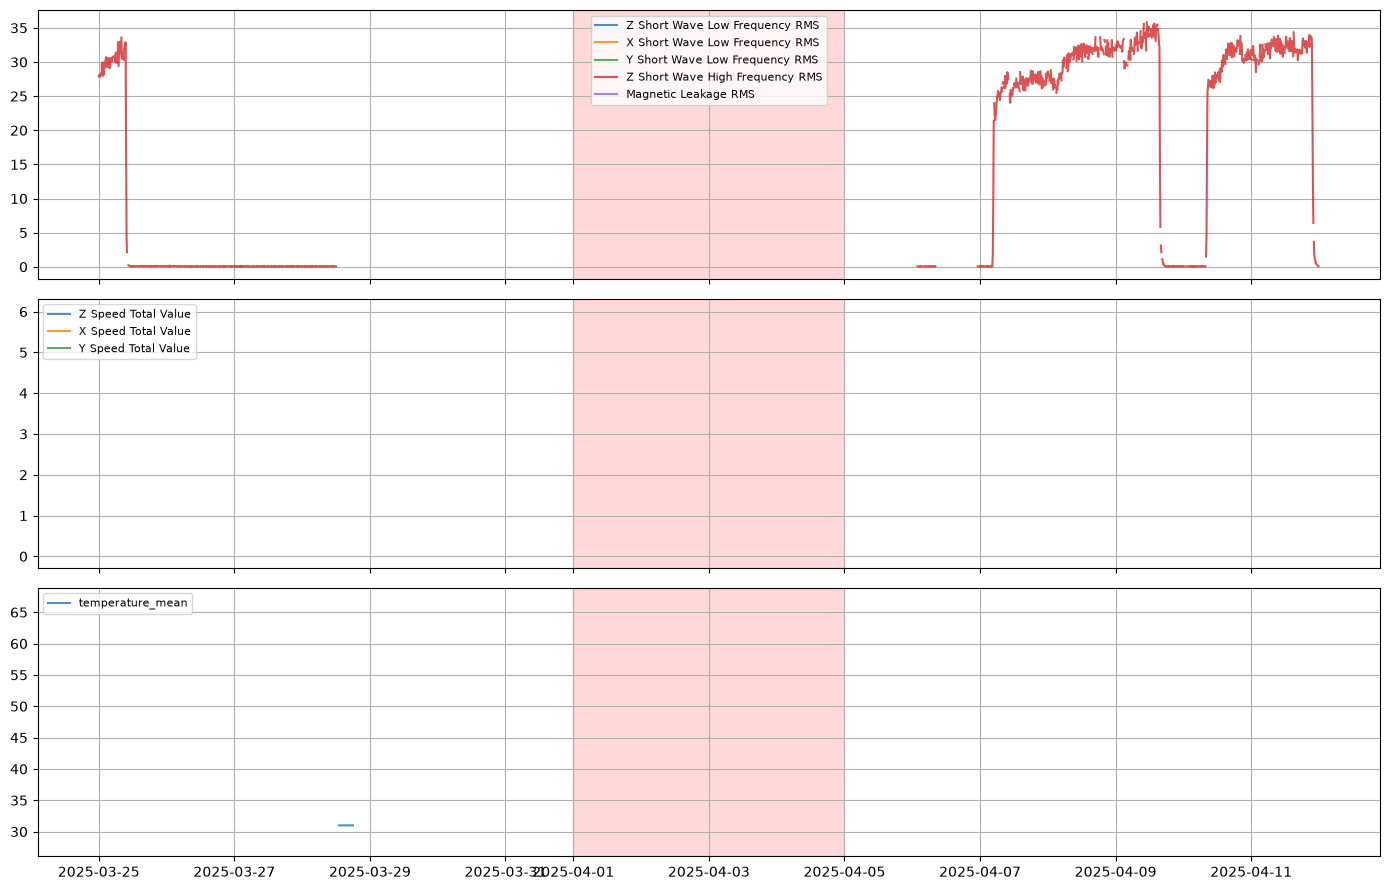

period                                           Labelled fault    Unlabelled
Motor DE_Z Short Wave Low Frequency RMS  count         0.000000   3356.000000
                                         median             NaN      2.403940
                                         mean               NaN      2.584945
                                         std                NaN      2.595216
Motor DE_X Short Wave Low Frequency RMS  count         0.000000    135.000000
                                         median             NaN      0.020120
                                         mean               NaN      2.277567
                                         std                NaN      4.446032
Motor DE_Y Short Wave Low Frequency RMS  count         0.000000    122.000000
                                         median             NaN      0.021040
                                         mean               NaN      2.656227
                                         std                NaN      5.989403
Motor DE_Z Speed Total Value             count         7.000000    737.000000
                                         median        0.053430      0.915500
                                         mean          0.054151      1.544154
                                         std           0.005119      1.785635
Motor DE_X Speed Total Value             count         7.000000    236.000000
                                         median        0.028430      0.068810
                                         mean          0.027967      1.747759
                                         std           0.002738      2.439652
Motor DE_Y Speed Total Value             count         7.000000     46.000000
                                         median        0.029730      0.034665
                                         mean          0.029034      0.480005
                                         std           0.003002      1.265819
Motor DE_Z Short Wave High Frequency RMS count         7.000000  19383.000000
                                         median        0.064840     16.264080
                                         mean          0.064983     12.926366
                                         std           0.000502     12.642878
Motor DE_Audio Decibels                  count         0.000000      5.000000
                                         median             NaN     26.454300
                                         mean               NaN     42.439408
                                         std                NaN     22.722898
Motor DE_Magnetic Leakage RMS            count         0.000000      5.000000
                                         median             NaN      5.643650
                                         mean               NaN      4.418028
                                         std                NaN      2.485062
temperature_mean                         count         0.000000   2700.000000
                                         median             NaN     39.000000
                                         mean               NaN     44.819630
                                         std                NaN     10.868665

period,Labelled fault,Unlabelled,fault_minus_unlabelled
Motor DE_Z Short Wave Low Frequency RMS,NaN,2.403940,NaN
Motor DE_X Short Wave Low Frequency RMS,NaN,0.020120,NaN
Motor DE_Y Short Wave Low Frequency RMS,NaN,0.021040,NaN
Motor DE_Z Speed Total Value,0.05343,0.915500,-0.862070
Motor DE_X Speed Total Value,0.02843,0.068810,-0.040380
Motor DE_Y Speed Total Value,0.02973,0.034665,-0.004935
Motor DE_Z Short Wave High Frequency RMS,0.06484,16.264080,-16.199240
Motor DE_Audio Decibels,NaN,26.454300,NaN
Motor DE_Magnetic Leakage RMS,NaN,5.643650,NaN
temperature_mean,NaN,39.000000,NaN


In [4]:
daily = df.set_index("date")[measure_cols].resample("1D").median()
fig, axes = plt.subplots(len(measure_cols), 1, figsize=(14, 2.4 * len(measure_cols)), sharex=True)
for ax, col in zip(np.atleast_1d(axes), measure_cols):
    ax.plot(daily.index, daily[col], linewidth=1)
    ax.axvspan(FAULT_START, FAULT_END, color="red", alpha=0.15)
    ax.set_ylabel(col.replace("Motor DE_", ""), fontsize=8)
plt.suptitle("Daily sensor medians; red shading = labelled fault")
plt.tight_layout()
plt.show()
near_fault = df[df["date"].between(FAULT_START - pd.Timedelta(days=7), FAULT_END + pd.Timedelta(days=7))]
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, token in zip(axes, ["RMS", "Speed Total Value", "temperature_mean"]):
    cols = [col for col in measure_cols if token in col]
    for col in cols:
        ax.plot(near_fault["date"], near_fault[col], label=col.replace("Motor DE_", ""), alpha=0.8)
    ax.axvspan(FAULT_START, FAULT_END, color="red", alpha=0.15)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(df.groupby("period")[measure_cols].agg(["count", "median", "mean", "std"]).T)
medians = df.groupby("period")[measure_cols].median().T
if {"Labelled fault", "Unlabelled"}.issubset(medians.columns):
    medians["fault_minus_unlabelled"] = medians["Labelled fault"] - medians["Unlabelled"]
display(medians)

## Correlations and candidate anomalies
The IQR rule flags unusual scalar values for investigation. It does not assign fault labels.

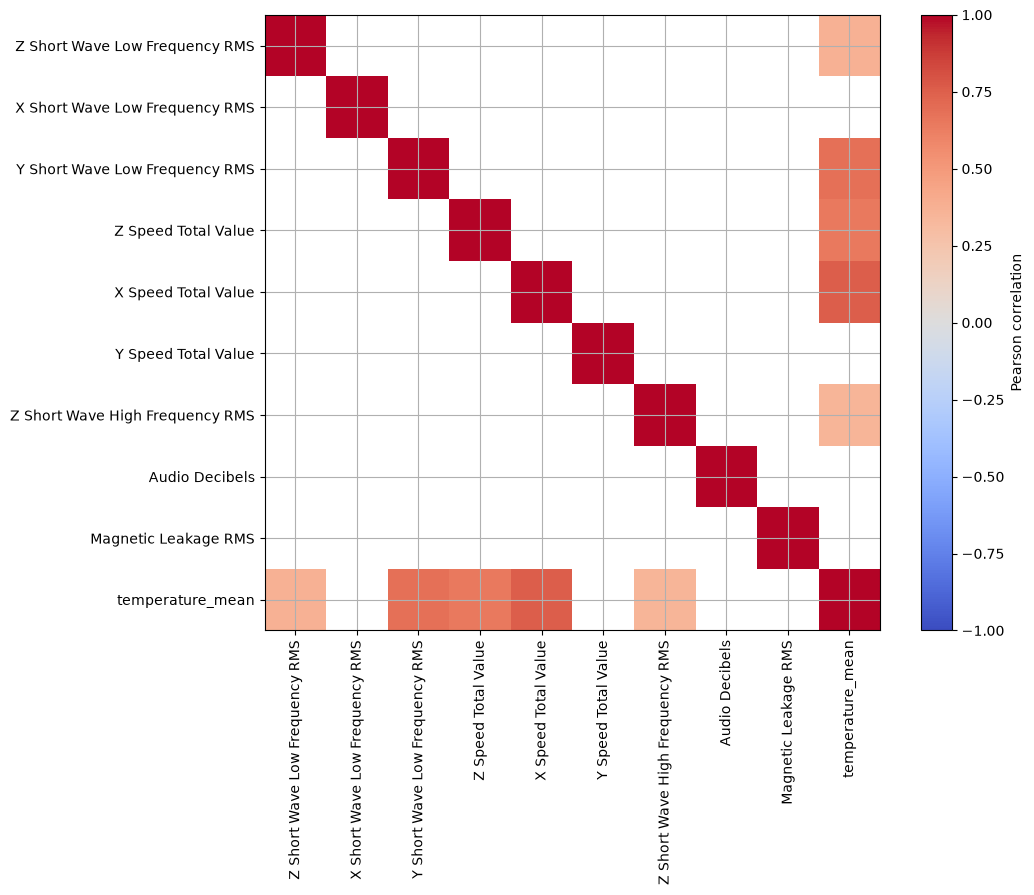

,IQR_outlier_pct
Motor DE_X Short Wave Low Frequency RMS,22.962963
Motor DE_Y Speed Total Value,22.641509
Motor DE_Magnetic Leakage RMS,20.000000
Motor DE_Y Short Wave Low Frequency RMS,19.672131
Motor DE_Z Speed Total Value,6.720430
Motor DE_Z Short Wave Low Frequency RMS,0.000000
Motor DE_X Speed Total Value,0.000000
Motor DE_Z Short Wave High Frequency RMS,0.000000
Motor DE_Audio Decibels,0.000000
temperature_mean,0.000000


,date,period,flagged_sensor_count,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,temperature_mean
5551,2025-02-10 00:01:20+00:00,Unlabelled,1,NaN,0.06304,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5553,2025-02-10 00:21:20+00:00,Unlabelled,1,NaN,NaN,0.07305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9779,2025-03-07 22:01:20+00:00,Unlabelled,1,NaN,NaN,NaN,8.52872,NaN,NaN,NaN,NaN,NaN,NaN
10013,2025-03-10 11:59:58+00:00,Unlabelled,1,NaN,NaN,NaN,6.09085,NaN,NaN,NaN,NaN,NaN,NaN
11002,2025-03-16 18:51:20+00:00,Unlabelled,1,NaN,NaN,NaN,NaN,NaN,0.22484,NaN,NaN,NaN,NaN
11006,2025-03-17 09:01:20+00:00,Unlabelled,1,NaN,NaN,NaN,NaN,NaN,0.18359,NaN,NaN,NaN,NaN
11010,2025-03-17 23:21:20+00:00,Unlabelled,1,NaN,NaN,NaN,NaN,NaN,0.27198,NaN,NaN,NaN,NaN
13408,2025-04-10 18:59:58+00:00,Unlabelled,1,NaN,NaN,NaN,5.04676,NaN,NaN,NaN,NaN,NaN,NaN
13424,2025-04-10 20:59:58+00:00,Unlabelled,1,NaN,NaN,NaN,5.19722,NaN,NaN,NaN,NaN,NaN,NaN
13559,2025-04-11 13:59:58+00:00,Unlabelled,1,NaN,NaN,NaN,5.61708,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
corr = df[measure_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
labels = [col.replace("Motor DE_", "") for col in measure_cols]
ax.set_xticks(range(len(labels)), labels, rotation=90)
ax.set_yticks(range(len(labels)), labels)
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()
q1, q3 = df[measure_cols].quantile(0.25), df[measure_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[measure_cols] < q1 - 1.5 * iqr) | (df[measure_cols] > q3 + 1.5 * iqr)) & df[measure_cols].notna()
display((100 * outliers.sum() / df[measure_cols].notna().sum()).sort_values(ascending=False).rename("IQR_outlier_pct").to_frame())
display(df.assign(flagged_sensor_count=outliers.sum(axis=1)).nlargest(15, "flagged_sensor_count")[["date", "period", "flagged_sensor_count"] + measure_cols])

## Representative waveforms
Read one low-frequency X-axis waveform from each period. Use sample index and cycles/sample until sampling rate and acceleration units are confirmed: the assignment contains inconsistencies in its metadata. These two records illustrate signals; they do not establish general differences between periods.

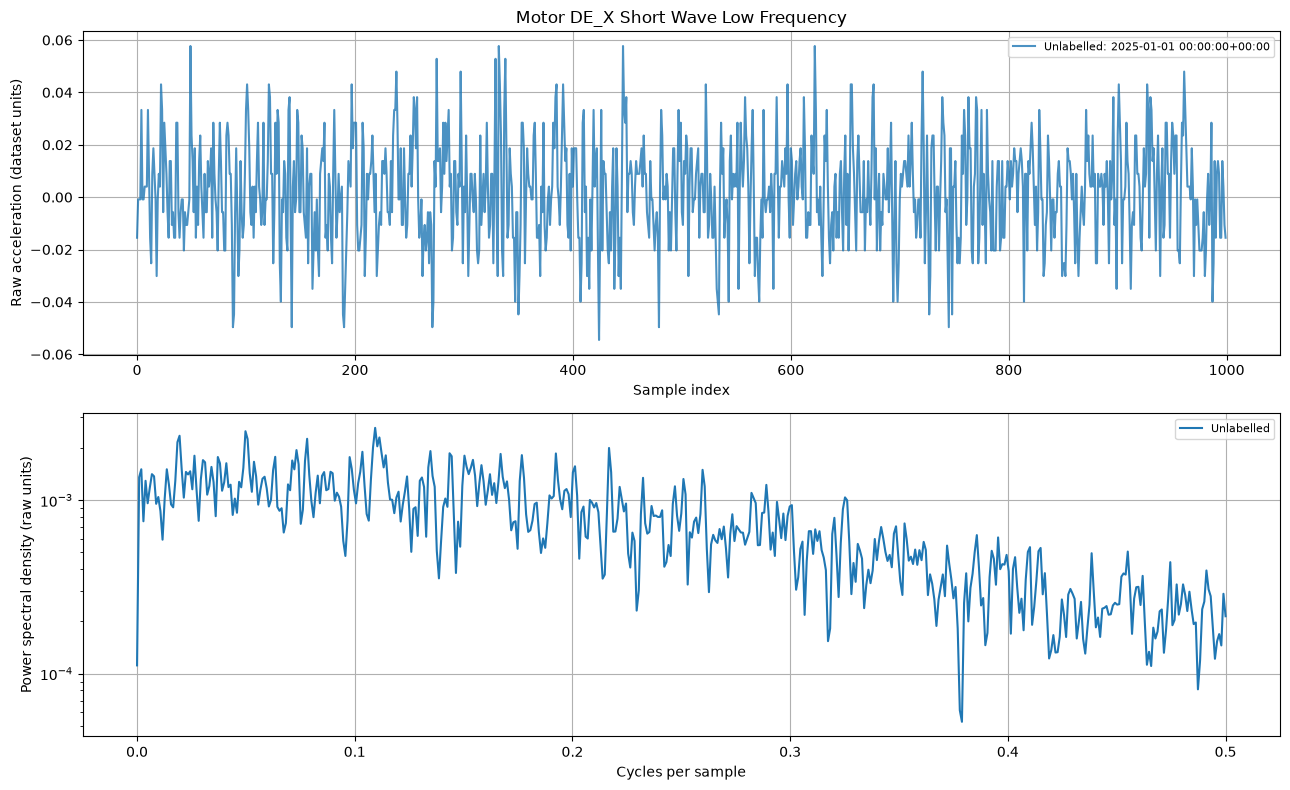

,period,date,samples,raw_rms,centered_rms,peak_to_peak,crest_factor
0,Unlabelled,2025-01-01 00:00:00+00:00,5120,0.019748,0.019748,0.1464,3.996844


In [6]:
from scipy import signal
WAVE_COL = "Motor DE_X Short Wave Low Frequency"
samples = {}
for batch in pf.iter_batches(batch_size=256, columns=["date", WAVE_COL]):
    chunk = batch.to_pandas()
    for date, value in chunk.itertuples(index=False, name=None):
        period = "Labelled fault" if FAULT_START <= date < FAULT_END else "Unlabelled"
        if period not in samples:
            a = finite_array(value)
            if a.size >= 8:
                samples[period] = (date, a)
    if len(samples) == 2:
        break
rows = []
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for period, (date, a) in samples.items():
    centered = a - a.mean()
    axes[0].plot(np.arange(min(1000, a.size)), a[:1000], label=f"{period}: {date}", alpha=0.8)
    freq, psd = signal.welch(centered, fs=1.0, nperseg=min(1024, a.size))
    axes[1].semilogy(freq, np.maximum(psd, np.finfo(float).tiny), label=period)
    rows.append({"period": period, "date": date, "samples": a.size,
                 "raw_rms": np.sqrt(np.mean(a**2)), "centered_rms": np.sqrt(np.mean(centered**2)),
                 "peak_to_peak": np.ptp(a), "crest_factor": np.max(np.abs(centered)) / np.sqrt(np.mean(centered**2)) if np.any(centered) else np.nan})
axes[0].set(xlabel="Sample index", ylabel="Raw acceleration (dataset units)", title=WAVE_COL)
axes[1].set(xlabel="Cycles per sample", ylabel="Power spectral density (raw units)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

## Findings to write after running the notebook
- What is the time coverage, collection cadence, and extent of missing or duplicated data?
- Which scalar signals change during the labelled fault period, and do those changes also occur outside it?
- Could load, machine shutdowns, temperature, or sensor quality explain the patterns?
- What waveform features deserve investigation across more records?
- Verify sampling rates, acceleration units, and label timezone before using the provided conversion functions. Keep the held-out evaluation period separate when moving to modelling.